# 陨石图像生成 -- Assignment 3
## DCGAN 训练 Notebook

**目标**：使用 DCGAN 在 2682 张陨石图像上训练生成模型，生成 1000 张新图像用于 FID 评估。

**目录结构**（评估前确认）：
```
assignment3/
├── evaluate_fid.py
├── inception_v3_google-0cc3c7bd.pth
├── meteorite/           # 2682 张训练图像
├── generated_pictures/  # [本 notebook 生成] 1000 张
└── evaluation_results/  # [evaluate_fid.py 生成]
```


In [3]:
from __future__ import annotations

import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
import torchvision.utils as vutils
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision.utils import make_grid
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == "cuda":
    print(f"  GPU: {torch.cuda.get_device_name(0)}")
    print(f" Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


Device: cuda
  GPU: NVIDIA L20
 Memory: 47.7 GB


In [4]:
SCRIPT_DIR = Path.cwd()
DATA_DIR = SCRIPT_DIR / "meteorite"
GENERATED_DIR = SCRIPT_DIR / "generated_pictures"
CHECKPOINT_DIR = SCRIPT_DIR / "checkpoints"
GRID_PATH = SCRIPT_DIR / "generated_grid.png"
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

assert DATA_DIR.is_dir(), f"未找到 {DATA_DIR}, 请确认 notebook 在 assignment3 根目录"
n_imgs = sum(1 for p in DATA_DIR.iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS)
print(f"数据目录: {DATA_DIR}")
print(f"图像数量: {n_imgs}")


数据目录: /data/Assignment3/meteorite
图像数量: 2682


In [5]:
class MeteoriteDataset(Dataset):
    """加载 meteorite/ 图像, 缩放到统一尺寸, 归一化到 [-1, 1]"""

    def __init__(self, image_dir: Path, image_size: int) -> None:
        self.image_paths = sorted(
            p for p in Path(image_dir).iterdir()
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        )
        if not self.image_paths:
            raise FileNotFoundError(f"目录中未找到图像: {image_dir}")

        self.transform = transforms.Compose([
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
        ])

    def __len__(self) -> int:
        return len(self.image_paths)

    def __getitem__(self, idx: int) -> torch.Tensor:
        img = Image.open(self.image_paths[idx]).convert("RGB")
        return self.transform(img)


In [6]:
class Generator(nn.Module):
    """DCGAN 生成器: latent_dim -> 64x64 RGB"""

    def __init__(self, latent_dim: int = 100, feature_maps: int = 64, channels: int = 3) -> None:
        super().__init__()
        self.latent_dim = latent_dim
        fm = feature_maps

        self.main = nn.Sequential(
            # (latent_dim, 1, 1) -> (fm*8, 4, 4)
            nn.ConvTranspose2d(latent_dim, fm * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(fm * 8),
            nn.ReLU(True),

            # -> (fm*4, 8, 8)
            nn.ConvTranspose2d(fm * 8, fm * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(fm * 4),
            nn.ReLU(True),

            # -> (fm*2, 16, 16)
            nn.ConvTranspose2d(fm * 4, fm * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(fm * 2),
            nn.ReLU(True),

            # -> (fm, 32, 32)
            nn.ConvTranspose2d(fm * 2, fm, 4, 2, 1, bias=False),
            nn.BatchNorm2d(fm),
            nn.ReLU(True),

            # -> (channels, 64, 64)
            nn.ConvTranspose2d(fm, channels, 4, 2, 1, bias=False),
            nn.Tanh(),
        )

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        return self.main(z.view(z.size(0), self.latent_dim, 1, 1))


In [7]:
class Discriminator(nn.Module):
    """DCGAN 判别器: 64x64 RGB -> 真假概率"""

    def __init__(self, feature_maps: int = 64, channels: int = 3) -> None:
        super().__init__()
        fm = feature_maps

        self.main = nn.Sequential(
            # (3, 64, 64) -> (fm, 32, 32)
            nn.Conv2d(channels, fm, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),

            # -> (fm*2, 16, 16)
            nn.Conv2d(fm, fm * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(fm * 2),
            nn.LeakyReLU(0.2, inplace=True),

            # -> (fm*4, 8, 8)
            nn.Conv2d(fm * 2, fm * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(fm * 4),
            nn.LeakyReLU(0.2, inplace=True),

            # -> (fm*8, 4, 4)
            nn.Conv2d(fm * 4, fm * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(fm * 8),
            nn.LeakyReLU(0.2, inplace=True),

            # -> (1, 1, 1)
            nn.Conv2d(fm * 8, 1, 4, 1, 0, bias=False),
            nn.Sigmoid(),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.main(x).view(-1)


In [8]:
def init_weights(model: nn.Module) -> None:
    """DCGAN 推荐初始化: Normal(0, 0.02) for Conv, Normal(1, 0.02) for BatchNorm"""
    for m in model.modules():
        if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
        elif isinstance(m, nn.BatchNorm2d):
            nn.init.normal_(m.weight, mean=1.0, std=0.02)
            nn.init.constant_(m.bias, 0.0)


In [9]:
def generate_fixed_noise(latent_dim: int, n: int, device: torch.device) -> torch.Tensor:
    """生成固定噪声用于训练中可视化进度"""
    return torch.randn(n, latent_dim, device=device)


def save_grid(generator, fixed_noise, path, device):
    """保存 3x3 九宫格预览图"""
    generator.eval()
    with torch.no_grad():
        fake = generator(fixed_noise).detach().cpu()
    grid = make_grid(fake, nrow=3, normalize=True, value_range=(-1, 1))
    vutils.save_image(grid, path)
    generator.train()


def generate_evaluation_images(generator, latent_dim, output_dir, device,
                               batch_size=50, total=1000):
    """生成 1000 张评估图像到 generated_pictures/"""
    output_dir.mkdir(parents=True, exist_ok=True)
    for old in output_dir.iterdir():
        if old.suffix.lower() in IMAGE_EXTENSIONS:
            old.unlink()

    generator.eval()
    generated = 0
    with torch.no_grad():
        while generated < total:
            n = min(batch_size, total - generated)
            z = torch.randn(n, latent_dim, device=device)
            fake = generator(z).detach().cpu()
            for i in range(fake.size(0)):
                vutils.save_image(
                    fake[i],
                    output_dir / f"{generated + i + 1:04d}.jpg",
                    normalize=True,
                    value_range=(-1, 1),
                )
            generated += n
    generator.train()
    print(f"已生成 {total} 张图像 -> {output_dir}")


In [10]:
# ==================== 超参数配置 ====================
IMAGE_SIZE = 64        # 生成/训练图像分辨率
LATENT_DIM = 100       # 噪声向量维度
FEATURE_MAPS = 64      # 生成器基础特征图数
BATCH_SIZE = 128       # 批大小
EPOCHS = 300           # 训练轮数
LR = 0.0002            # 学习率
BETA1 = 0.5            # Adam beta1
NUM_WORKERS = 4        # DataLoader 进程数
SEED = 42              # 随机种子
SAVE_INTERVAL = 50     # checkpoint 保存间隔 (epoch)

# GPU 显存参考:
#   6GB  -> BATCH_SIZE=64
#   12GB -> BATCH_SIZE=128
#   24GB -> BATCH_SIZE=256

print(f"图像分辨率: {IMAGE_SIZE}x{IMAGE_SIZE}")
print(f"Batch Size:  {BATCH_SIZE}")
print(f"Epochs:      {EPOCHS}")
print(f"Learning Rate: {LR}")


图像分辨率: 64x64
Batch Size:  128
Epochs:      300
Learning Rate: 0.0002


In [11]:
# ==================== 可复现性 ====================
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ==================== 数据加载 ====================
dataset = MeteoriteDataset(DATA_DIR, IMAGE_SIZE)
dataloader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
    drop_last=True,
)
print(f"训练集: {len(dataset)} 张图像, {len(dataloader)} 个 batch/epoch")

sample_batch = next(iter(dataloader))
print(f"Batch shape: {sample_batch.shape}  (应为 [{BATCH_SIZE}, 3, {IMAGE_SIZE}, {IMAGE_SIZE}])")


训练集: 2682 张图像, 20 个 batch/epoch
Batch shape: torch.Size([128, 3, 64, 64])  (应为 [128, 3, 64, 64])


In [12]:
# ==================== 模型初始化 ====================
netG = Generator(LATENT_DIM, FEATURE_MAPS, 3).to(device)
netD = Discriminator(FEATURE_MAPS, 3).to(device)
netG.apply(init_weights)
netD.apply(init_weights)

print(f"Generator 参数量:      {sum(p.numel() for p in netG.parameters()):,}")
print(f"Discriminator 参数量:  {sum(p.numel() for p in netD.parameters()):,}")

# ==================== 优化器 & 损失 ====================
optimizerG = optim.Adam(netG.parameters(), lr=LR, betas=(BETA1, 0.999))
optimizerD = optim.Adam(netD.parameters(), lr=LR, betas=(BETA1, 0.999))
criterion = nn.BCELoss()

fixed_noise = generate_fixed_noise(LATENT_DIM, 9, device)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
print("模型已初始化, 准备训练...")


Generator 参数量:      3,576,704
Discriminator 参数量:  2,765,568
模型已初始化, 准备训练...


In [13]:
# ==================== 训练循环 ====================
g_losses = []
d_losses = []

for epoch in range(1, EPOCHS + 1):
    pbar = tqdm(dataloader, desc=f"Epoch {epoch}/{EPOCHS}", leave=False)
    epoch_g_loss = 0.0
    epoch_d_loss = 0.0

    for real in pbar:
        batch_size_curr = real.size(0)
        real = real.to(device)

        # ---- 训练判别器 D ----
        netD.zero_grad()

        label_real = torch.full((batch_size_curr,), 1.0, device=device)
        errD_real = criterion(netD(real), label_real)

        z = torch.randn(batch_size_curr, LATENT_DIM, device=device)
        fake = netG(z).detach()
        label_fake = torch.full((batch_size_curr,), 0.0, device=device)
        errD_fake = criterion(netD(fake), label_fake)

        errD = errD_real + errD_fake
        errD.backward()
        optimizerD.step()

        # ---- 训练生成器 G ----
        netG.zero_grad()
        z = torch.randn(batch_size_curr, LATENT_DIM, device=device)
        fake = netG(z)
        errG = criterion(netD(fake), torch.full((batch_size_curr,), 1.0, device=device))

        errG.backward()
        optimizerG.step()

        epoch_d_loss += errD.item()
        epoch_g_loss += errG.item()
        pbar.set_postfix(D=f"{errD.item():.3f}", G=f"{errG.item():.3f}")

    avg_d = epoch_d_loss / len(dataloader)
    avg_g = epoch_g_loss / len(dataloader)
    g_losses.append(avg_g)
    d_losses.append(avg_d)

    if epoch % 10 == 0 or epoch == 1 or epoch == EPOCHS:
        print(f"[Epoch {epoch:3d}/{EPOCHS}]  D_loss: {avg_d:.4f}  G_loss: {avg_g:.4f}")

    if epoch % SAVE_INTERVAL == 0 or epoch == EPOCHS:
        torch.save({
            "epoch": epoch,
            "generator_state_dict": netG.state_dict(),
            "discriminator_state_dict": netD.state_dict(),
            "optimizerG_state_dict": optimizerG.state_dict(),
            "optimizerD_state_dict": optimizerD.state_dict(),
            "g_losses": g_losses,
            "d_losses": d_losses,
        }, CHECKPOINT_DIR / f"checkpoint_epoch_{epoch:04d}.pth")

        save_grid(netG, fixed_noise, GRID_PATH, device)
        print(f"  -> 已保存 checkpoint & 九宫格 (epoch {epoch})")

print("\n训练完成!")


[Epoch   1/300]  D_loss: 0.3438  G_loss: 8.6189


[Epoch  10/300]  D_loss: 0.2272  G_loss: 3.6439


[Epoch  20/300]  D_loss: 0.9575  G_loss: 2.7934


[Epoch  30/300]  D_loss: 0.6527  G_loss: 2.9635


[Epoch  40/300]  D_loss: 1.0204  G_loss: 2.6897


...

[Epoch 260/300]  D_loss: 0.0965  G_loss: 4.3276


[Epoch 270/300]  D_loss: 0.0609  G_loss: 4.6639


[Epoch 280/300]  D_loss: 1.9087  G_loss: 1.5925


[Epoch 290/300]  D_loss: 0.0707  G_loss: 4.6466


[Epoch 300/300]  D_loss: 0.0438  G_loss: 4.9361
  -> 已保存 checkpoint & 九宫格 (epoch 300)

训练完成!


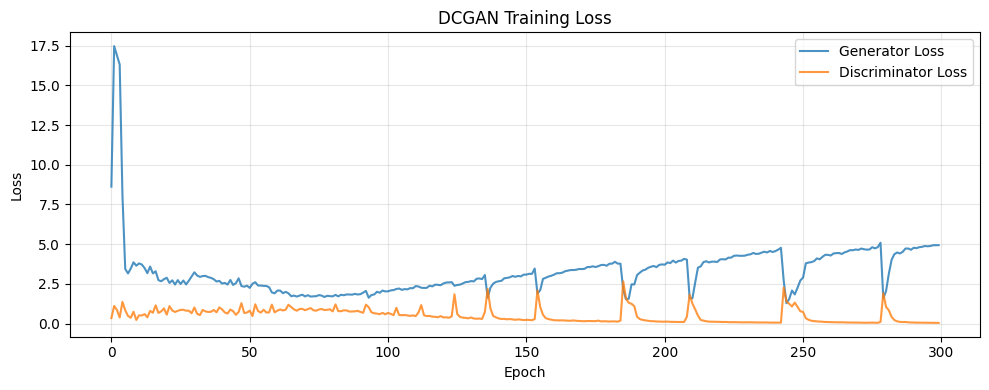

In [14]:
# ==================== 损失曲线 ====================
plt.figure(figsize=(10, 4))
plt.plot(g_losses, label="Generator Loss", alpha=0.8)
plt.plot(d_losses, label="Discriminator Loss", alpha=0.8)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DCGAN Training Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(SCRIPT_DIR / "training_loss.png", dpi=100)
plt.show()


In [15]:
# ==================== 生成 1000 张评估图像 ====================
best_checkpoint = sorted(CHECKPOINT_DIR.glob("checkpoint_epoch_*.pth"))[-1]
print(f"加载 checkpoint: {best_checkpoint.name}")
checkpoint = torch.load(best_checkpoint, map_location=device, weights_only=True)
netG.load_state_dict(checkpoint["generator_state_dict"])

generate_evaluation_images(netG, LATENT_DIM, GENERATED_DIR, device)

gen_count = sum(1 for p in GENERATED_DIR.iterdir()
                if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
print(f"generated_pictures/ 图像数量: {gen_count}")
assert gen_count == 1000, f"期望 1000 张, 实际 {gen_count} 张!"
print("\n现在可以运行: python evaluate_fid.py")


加载 checkpoint: checkpoint_epoch_0300.pth
已生成 1000 张图像 -> /data/Assignment3/generated_pictures
generated_pictures/ 图像数量: 1000

现在可以运行: python evaluate_fid.py


报告九宫格已保存: /data/Assignment3/report_3x3_grid.png


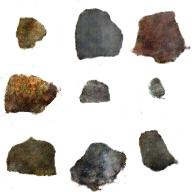

In [16]:
# ==================== 报告用 3x3 九宫格 ====================
# 从生成图像中随机选 9 张 -- 建议手动替换为视觉效果最好的 9 张

all_generated = sorted(
    p for p in GENERATED_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

selected = random.sample(all_generated, 9)
images = [Image.open(p) for p in selected]

grid_img = Image.new("RGB", (IMAGE_SIZE * 3, IMAGE_SIZE * 3), "white")
for idx, img in enumerate(images):
    row, col = divmod(idx, 3)
    grid_img.paste(img.resize((IMAGE_SIZE, IMAGE_SIZE)),
                   (col * IMAGE_SIZE, row * IMAGE_SIZE))

report_grid_path = SCRIPT_DIR / "report_3x3_grid.png"
grid_img.save(report_grid_path)
print(f"报告九宫格已保存: {report_grid_path}")
display(grid_img)


## 下一步

1. **评估 FID**：在终端运行 `python evaluate_fid.py`
2. **挑选最佳 9 张**：从 `generated_pictures/` 中手动挑选视觉效果最好的 9 张图像，替换上面 Cell 中的随机选择，重新生成报告九宫格
3. **撰写报告** (`report.pdf`)：
   - 方法说明（DCGAN 架构、关键设计选择）
   - 训练参数表
   - FID 分数（来自 `evaluation_results/fid_metrics.json`）
   - 3x3 九宫格图
   - 实验分析与改进方向
4. **打包提交**：
   - `student_id_name_assignment3_report.pdf`
   - `student_id_name_assignment3_code.zip`（仅代码，不含数据/图像/权重/checkpoint）


In [17]:
!python evaluate_fid.py

Device: cuda
Reference images: /data/Assignment3/meteorite (2682 images)
Generated images: /data/Assignment3/generated_pictures (1000 images)
Output dir: /data/Assignment3/evaluation_results
Feature weights: imagenet
/data/Assignment3/evaluate_fid.py:171: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = linalg.sqrtm(sigma_real @ sigma_generated, disp=False)
FID: 245.9168
Metrics saved: /data/Assignment3/evaluation_results/fid_metrics.json
